## SkyTEM L2 Occam's inversion

In [15]:
using PyPlot, DelimitedFiles, Random, Statistics,
      HiQGA
cd(@__DIR__)

  Activating project at `~/.julia/environments/HiQGA_stable`


## Model discretization

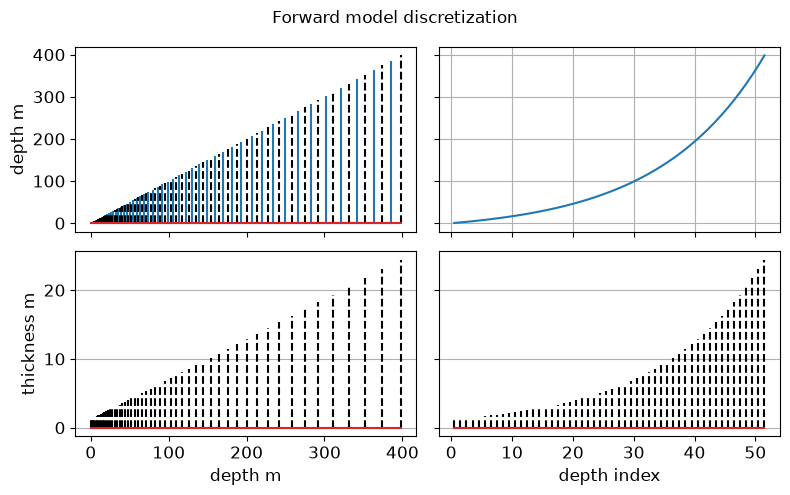

true

In [16]:
# model fixed parts, i.e., air
zfixed   = [-1e5]
ρfixed   = [1e12]
# Note that the receiver and transmitter need to be in air
zstart = 0.0
extendfrac, dz = 1.06, 1.25
nlayers = 52
zall, znall, zboundaries = transD_GP.setupz(zstart, extendfrac, dz=dz, n=nlayers, showplot=true)
z, ρ, nfixed = transD_GP.makezρ(zboundaries; zfixed=zfixed, ρfixed=ρfixed)
# Rx, Tx geometry and modeling parameters
rRx = 13.
zRx = -42.0
zTx = -40.0
# read waveform, window times, noise
include("../00_required/skytem_electronics_halt.jl")
calcjacobian = true

## make SkyTEM operator

In [17]:
# use variables defined in skytem_electronics_halt
aem = transD_GP.SkyTEM1DInversion.dBzdt(;
    timeslow = LM_times, ramplow = LM_ramp, zRxlow=zRx, zTxlow = zTx,
    timeshigh = HM_times, ramphigh = HM_ramp, zRxhigh=zRx, zTxhigh = zTx,
    rRx, rTx, z, ρ, lowpassfcs, calcjacobian);

## Construct synthetic model and plot data

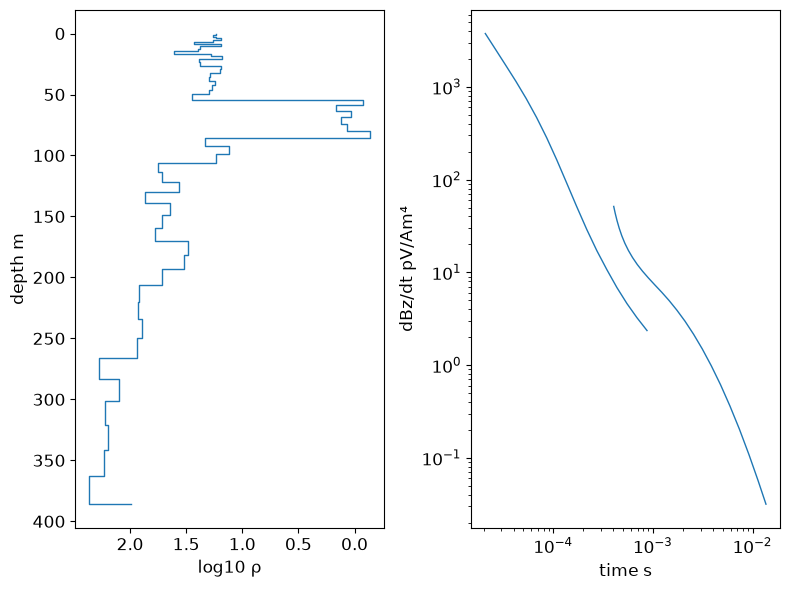

In [18]:
# fill in detail in ohm-m
ρ[(z.>=zstart) .& (z.<50)] .= 20.
ρ[(z.>=50) .&(z.<80)]      .= 1
ρ[(z.>=80) .&(z.<100)]     .= 20
ρ[(z.>=100) .&(z.<200)]    .= 50
ρ[(z.>=200) .&(z.<250)]    .= 80
ρ[(z.>=250)]               .= 150
# add jitter to model in log10 domain
Random.seed!(11)
ρ = 10 .^(0.1*randn(length(ρ)) + log10.(ρ))
# plot it
transD_GP.SkyTEM1DInversion.plotmodelfield!(aem, log10.(ρ[2:end]));

## add noise to data and plot

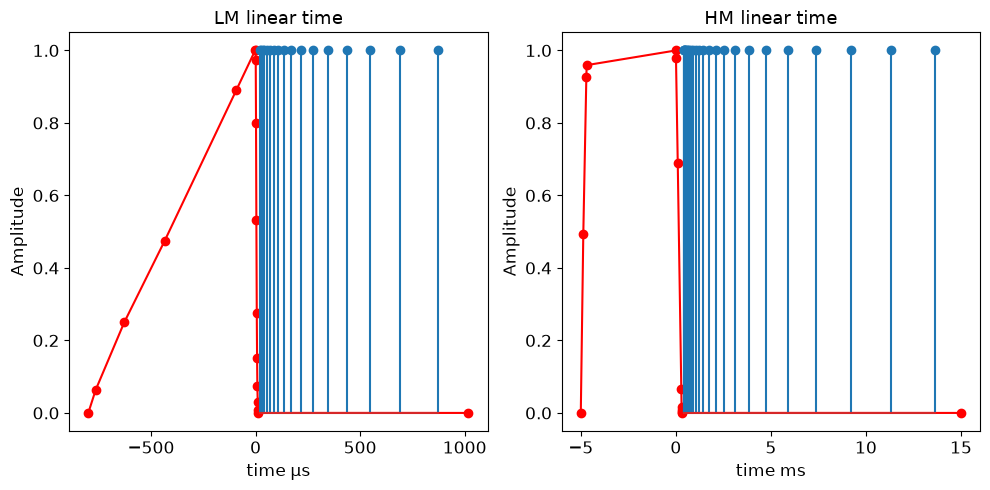

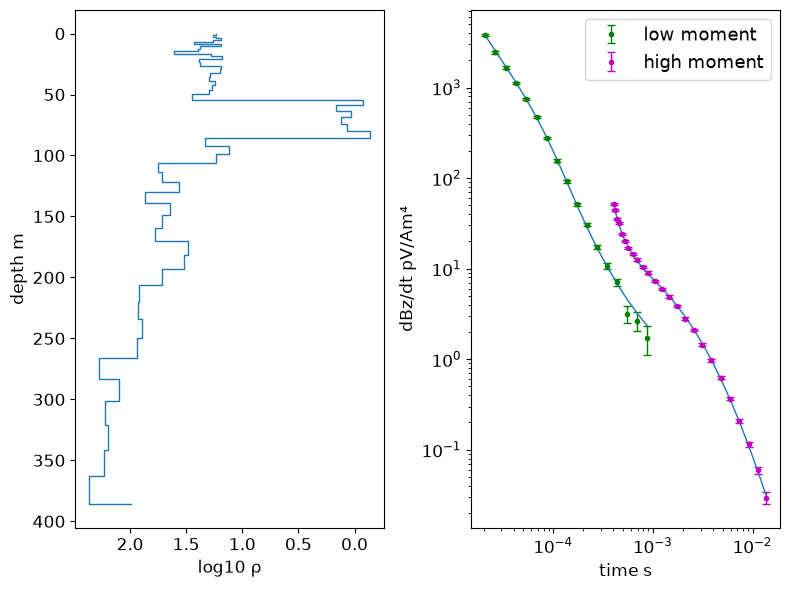

In [19]:
transD_GP.SkyTEM1DInversion.makenoisydata!(aem, log10.(ρ[2:end]);
    σ_halt_low=LM_noise, σ_halt_high=HM_noise,
    units = 1e-12)

## Gradient descent options

In [20]:
# for gradient descent, all model values are in log10 conductivity
# create empty log10 conductivity arrays for start and background
σstart      = -2*ones(length(zall))
σ0          = -2*ones(length(zall)) # prior model
lo          = -3      # log10 min conductivity
hi          = 1       # log10 max conductivity
λ²min       = 0       # min log10 of Tikhonov parameter
λ²max       = 7.      # max log10 of Tikhonov parameter
ntries      = 10      # how many max tries between λ²min, λ²max
β²          = 0.001   # what fraction of roughness penalty to use to enforce a penalty in deviations from background
knownvalue  = 0.7     # cutoff to start next Gauss-Newton step
nstepsmax   = 20      # Gauss-Newton steps
regtype     = :R1     # :R1 is first difference regularization, :R2 is two succesive first differences

:R1

## Do inversion!

In [21]:
m, χ², λ², idx = transD_GP.gradientinv(σstart, σ0, aem,
                            ;λ²min, λ²max, β²,
                            ntries, nstepsmax, knownvalue,
                            lo, hi, regtype);

[ Info: iteration: 1 χ²: 10604.95728448861 target: 42
[ Info: iteration: 2 χ²: 4659.920317357992 target: 42
[ Info: iteration: 3 χ²: 1655.8819284605872 target: 42
[ Info: iteration: 4 χ²: 794.0941801200441 target: 42
[ Info: iteration: 5 χ²: 110.55933859278973 target: 42
[ Info: iteration: 6 χ²: 41.9999999999999 target: 42


## Plot each iteration of descent

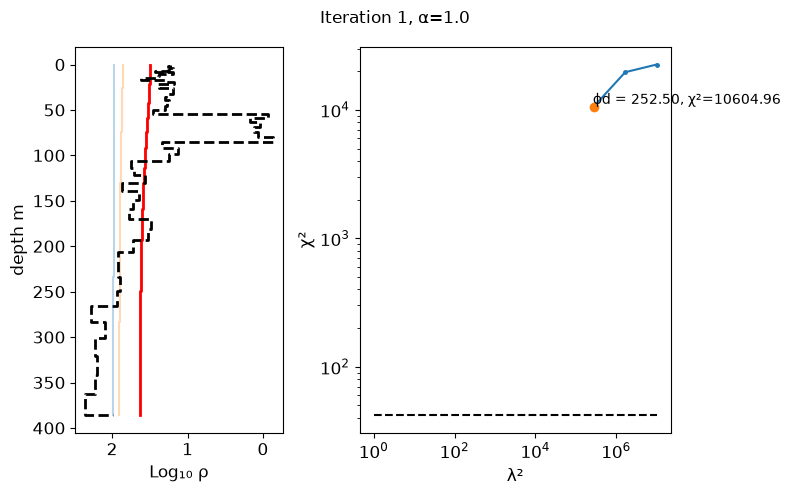

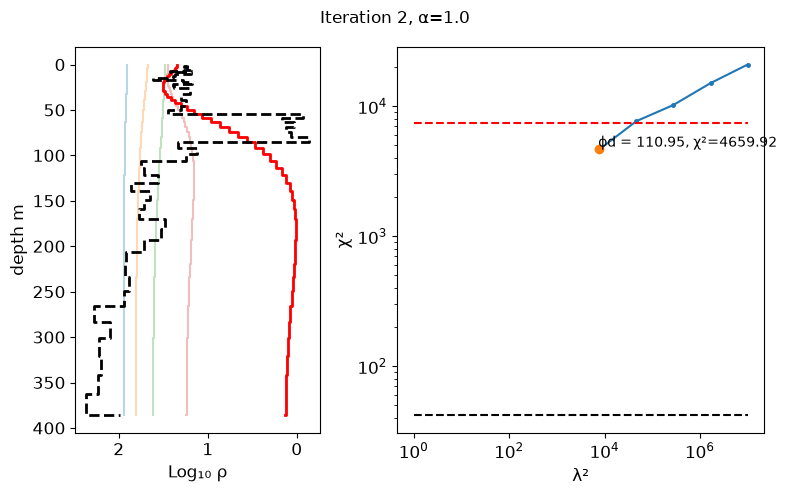

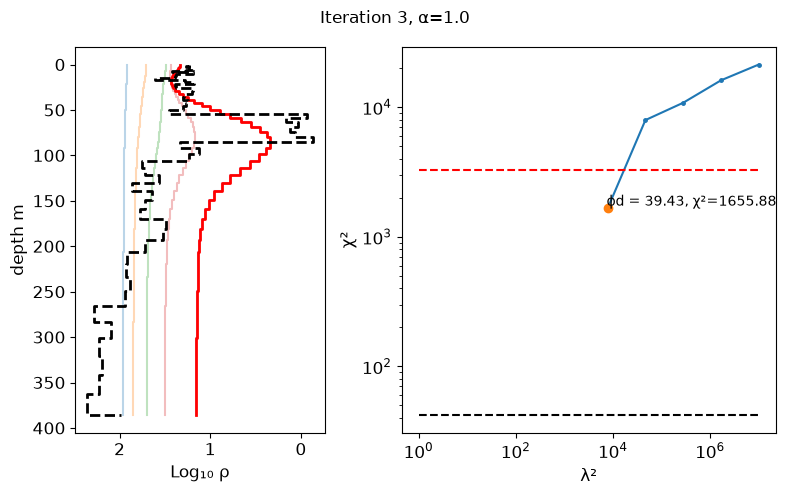

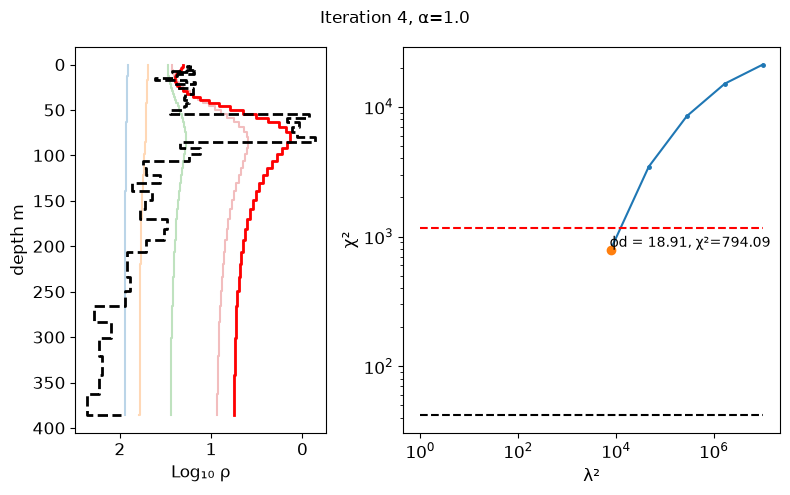

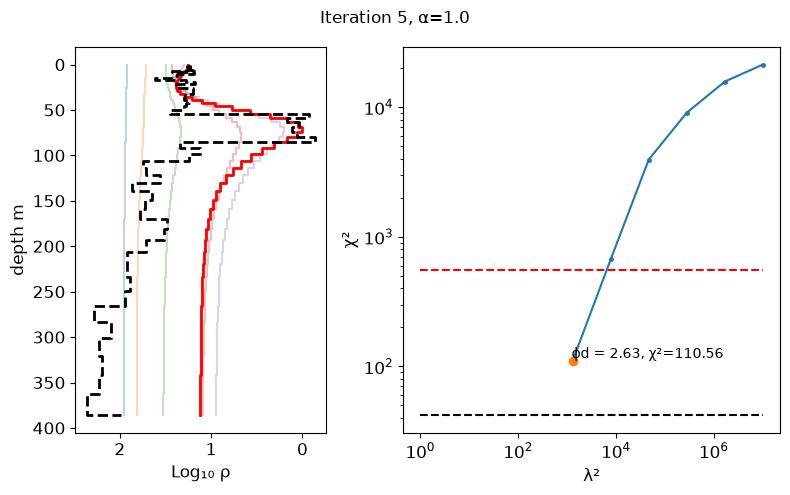

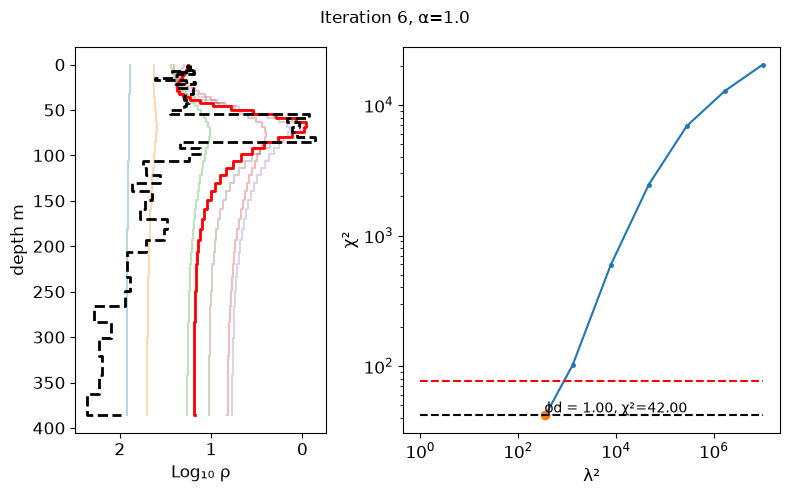

In [22]:
# inner plots for each outer iteration
using Printf
alpha = 0.3
ndata = length(aem.res)
for (i, mi) in enumerate(m)
    f, s = plt.subplots(1, 2, gridspec_kw=Dict("width_ratios" => [1,1.5]),
        figsize=(8,5))
    for ii in 1:length(χ²[i])
        s[1].step(-mi[ii], aem.z[2:end], alpha=alpha)
    end
    s[1].step(-mi[idx[i]], aem.z[2:end], color="r", linewidth=2)
    s[1].step(log10.(ρ[2:end]), z[2:end], color="k", linewidth=2, linestyle="--")
    s[1].set_ylabel("depth m")
    s[1].set_xlabel("Log₁₀ ρ")
    s[1].invert_yaxis()
    s[1].invert_xaxis()
    hps = hcat(λ²[i]...)'
    sortedλidx = sortperm(hps[:,1])
    sortedαidx = sortperm(hps[:,2])
    s[2].loglog(hps[sortedλidx,1], χ²[i][sortedλidx], ".-", markersize=5)
    s[2].plot(hps[idx[i],1], χ²[i][idx[i]], "o" )
    s[2].text(.95hps[idx[i],1], 1.05χ²[i][idx[i]], "ϕd = $(@sprintf("%.2f", χ²[i][idx[i]]/ndata)), χ²=$(@sprintf("%.2f", χ²[i][idx[i]]))" )
    if i>1
        targ = knownvalue*χ²[i-1][idx[i-1]]
        s[2].plot(10.0 .^[λ²min, λ²max], [targ, targ], "--r")
    end
    s[2].plot(10.0 .^[λ²min, λ²max], [ndata, ndata], "--k")
    s[2].set_ylabel("χ²")
    s[2].set_xlabel("λ²")
    plt.suptitle("Iteration $i, α=$(hps[idx[i],2])")
    transD_GP.nicenup(f, fsize=12)
end

## Plots for best in each outer iteration

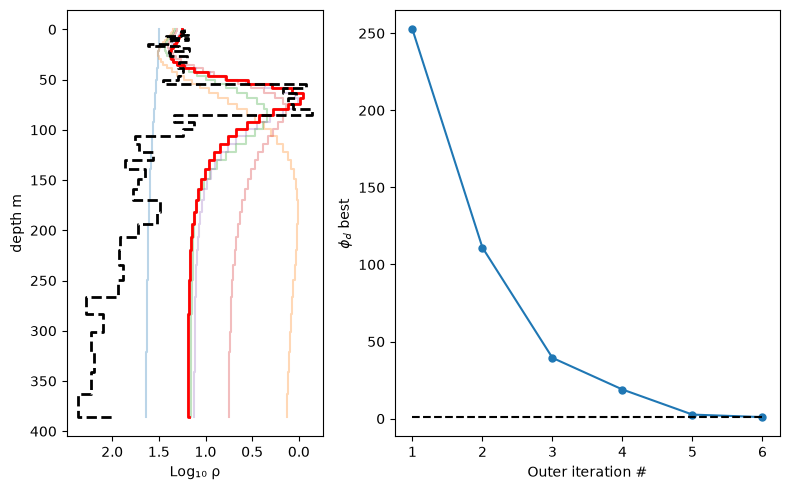

In [23]:
f, s = plt.subplots(1, 2, gridspec_kw=Dict("width_ratios" => [1,1.5]),
        figsize=(8,5))
alpha = 0.3
χ²best = zeros(0)
idxlast = length(m)
ndata = length(aem.res)
for (i, mi) in enumerate(m)
    s[1].step(-mi[idx[i]], aem.z[2:end], alpha=alpha)
    push!(χ²best, minimum(χ²[i]))
    i == idxlast && break
end
s[1].step(-m[idxlast][idx[idxlast]], aem.z[2:end], color="r", linewidth=2)
s[1].step(log10.(ρ[2:end]), z[2:end], color="k", linewidth=2, linestyle="--")
s[1].invert_yaxis()
s[1].invert_xaxis()
s[1].set_ylabel("depth m")
s[1].set_xlabel("Log₁₀ ρ")
s[2].plot(1:idxlast, χ²best/ndata, ".-", ms=10)
s[2].plot([1, idxlast], [1, 1], "--k")
s[2].set_xlabel("Outer iteration #")
s[2].set_ylabel(L"ϕ_d"*" best")
f.tight_layout()

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*